In [5]:
import requests
import numpy as np
import pandas as pd
import tensorflow as tf

# ==========================================
# 1. FETCH REAL HISTORICAL DATA (OPEN-METEO)
# ==========================================
# Set coordinates to target deployment location (e.g., Goa, India)
LATITUDE = 15.39
LONGITUDE = 73.88
START_DATE = "2020-01-01"
END_DATE = "2025-12-31"

url = (
    f"https://archive-api.open-meteo.com/v1/archive?"
    f"latitude={LATITUDE}&longitude={LONGITUDE}"
    f"&start_date={START_DATE}&end_date={END_DATE}"
    f"&hourly=temperature_2m,relative_humidity_2m,surface_pressure,precipitation"
    f"&timezone=auto"
)

print("Downloading historical weather data...")
response = requests.get(url).json()
df = pd.DataFrame(response["hourly"])
df.dropna(inplace=True)
print(f"Downloaded {len(df)} hourly records.")

# ==========================================
# 2. CREATE SLIDING WINDOWS & AUTO-LABELS
# ==========================================
WINDOW_SIZE = 12      # Past 12 hours of sensor readings
FORECAST_HORIZON = 3  # Predict weather trend over the next 3 hours

features = df[["temperature_2m", "relative_humidity_2m", "surface_pressure"]].values
precip = df["precipitation"].values
pressure = df["surface_pressure"].values

X_windows, y_labels = [], []

for i in range(len(df) - WINDOW_SIZE - FORECAST_HORIZON):
    # Input: 12 consecutive readings of [Temp, Humidity, Pressure]
    window = features[i : i + WINDOW_SIZE]

    # Future target: look at precipitation and pressure delta over the next 3 hours
    future_rain = np.sum(precip[i + WINDOW_SIZE : i + WINDOW_SIZE + FORECAST_HORIZON])
    pressure_delta = pressure[i + WINDOW_SIZE + FORECAST_HORIZON - 1] - pressure[i + WINDOW_SIZE - 1]

    # Class 0: Stable / Clear
    # Class 1: Rain / Unsettled (rain > 0.5mm or sharp pressure drop)
    # Class 2: Clearing / Rising Pressure (no rain and pressure rising > 1.0 hPa)
    if future_rain > 0.5 or pressure_delta < -1.2:
        label = 1
    elif pressure_delta > 1.0:
        label = 2
    else:
        label = 0

    X_windows.append(window)
    y_labels.append(label)

X = np.array(X_windows, dtype=np.float32)
y = np.array(y_labels, dtype=np.int32)

print(f"Total windows: {len(X)} | Class distribution: {np.bincount(y)}")

# ==========================================
# 3. CHRONOLOGICAL TRAIN / VAL / TEST SPLIT
# ==========================================
# Strict chronological split prevents sliding-window data leakage
n_total = len(X)
train_end = int(0.70 * n_total)
val_end = int(0.85 * n_total)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val     = X[train_end:val_end], y[train_end:val_end]
X_test, y_test   = X[val_end:], y[val_end:]

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# ==========================================
# 4. NORMALIZATION (FIT ON TRAIN ONLY!)
# ==========================================
mean = X_train.mean(axis=(0, 1))
std = X_train.std(axis=(0, 1)) + 1e-7

X_train_norm = (X_train - mean) / std
X_val_norm   = (X_val - mean) / std
X_test_norm  = (X_test - mean) / std

print("\n--- COPY INTO YOUR STM32 FIRMWARE ---")
print(f"const float FEATURE_MEAN[3] = {{{mean[0]:.4f}f, {mean[1]:.4f}f, {mean[2]:.4f}f}};")
print(f"const float FEATURE_STD[3]  = {{{std[0]:.4f}f, {std[1]:.4f}f, {std[2]:.4f}f}};")
print("-------------------------------------\n")

# ==========================================
# 5. TRAIN 1D-CNN WITH CLASS WEIGHTS
# ==========================================
# Weather datasets are naturally imbalanced (more clear hours than storms).
# Class weights prevent the model from just guessing "Clear" every time.
class_counts = np.bincount(y_train)
total_train = len(y_train)
class_weights = {i: total_train / (3.0 * count) for i, count in enumerate(class_counts)}

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, 3)),
    tf.keras.layers.Conv1D(16, kernel_size=3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling1D(pool_size=2),
    tf.keras.layers.Conv1D(8, kernel_size=3, activation="relu", padding="same"),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

model.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=40,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

# ==========================================
# 6. FINAL TEST EVALUATION & INT8 EXPORT
# ==========================================
test_loss, test_acc = model.evaluate(X_test_norm, y_test, verbose=0)
print(f"\nUnseen Test Set Accuracy (Float32): {test_acc * 100:.2f}%")

def representative_dataset():
    for i in range(200):
        yield [np.expand_dims(X_train_norm[i], axis=0).astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_quant_model = converter.convert()
with open("weather_trend_int8.tflite", "wb") as f:
    f.write(tflite_quant_model)

print(f"Exported weather_trend_int8.tflite ({len(tflite_quant_model)} bytes)")

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ==========================================
# 7. RUN INFERENCE WITH QUANTIZED INT8 MODEL
# ==========================================
interpreter = tf.lite.Interpreter(model_content=tflite_quant_model)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]
in_scale, in_zero = input_details["quantization"]
out_scale, out_zero = output_details["quantization"]

y_pred_int8 = []
y_prob_rain = []

for i in range(len(X_test_norm)):
    # Quantize normalized float input -> int8
    q_in = np.clip(np.round((X_test_norm[i] / in_scale) + in_zero), -128, 127).astype(np.int8)
    interpreter.set_tensor(input_details["index"], np.expand_dims(q_in, axis=0))
    interpreter.invoke()

    # Dequantize int8 output -> probability
    q_out = interpreter.get_tensor(output_details["index"])[0]
    probs = (q_out.astype(np.float32) - out_zero) * out_scale

    y_pred_int8.append(np.argmax(probs))
    y_prob_rain.append(probs[1])  # Probability of Class 1 (Rain / Unsettled)

y_pred_int8 = np.array(y_pred_int8)
y_prob_rain = np.array(y_prob_rain)

class_names = ["Stable (0)", "Rain/Storm (1)", "Clearing (2)"]
print("\n--- INT8 QUANTIZED TEST CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred_int8, target_names=class_names))

Downloaded 52608 hourly records.
Total windows: 52593 | Class distribution: [13423 26071 13099]
Train: 36815 | Val: 7889 | Test: 7889

--- COPY INTO YOUR STM32 FIRMWARE ---
const float FEATURE_MEAN[3] = {26.6869f, 76.7645f, 996.7264f};
const float FEATURE_STD[3]  = {3.2622f, 17.8211f, 4.7377f};
-------------------------------------

Epoch 1/40
576/576 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5771 - loss: 0.9413 - val_accuracy: 0.6684 - val_loss: 0.7842
Epoch 2/40
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6837 - loss: 0.7426 - val_accuracy: 0.7172 - val_loss: 0.6577
Epoch 3/40
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7273 - loss: 0.6355 - val_accuracy: 0.7386 - val_loss: 0.6162
Epoch 4/40
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7491 - loss: 0.5939 - val_accuracy: 0.7614 - val_loss: 0.5705
Epoch 5/40
576/576 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7587 - loss: 0.5743 - val_accuracy: 0.7647 - val_loss: 0.5623
Epoch 6/40
576/576 ━━━━━━

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Exported weather_trend_int8.tflite (8104 bytes)

--- INT8 QUANTIZED TEST CLASSIFICATION REPORT ---
                precision    recall  f1-score   support

    Stable (0)       0.68      0.70      0.69      1890
Rain/Storm (1)       0.88      0.83      0.86      4326
  Clearing (2)       0.77      0.84      0.80      1673

      accuracy                           0.81      7889
     macro avg       0.78      0.79      0.78      7889
  weighted avg       0.81      0.81      0.81      7889



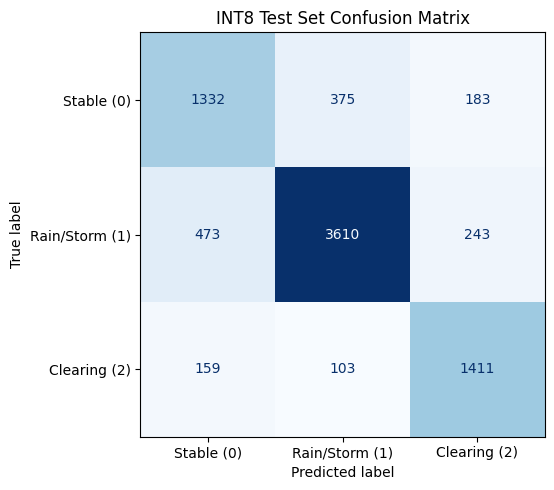

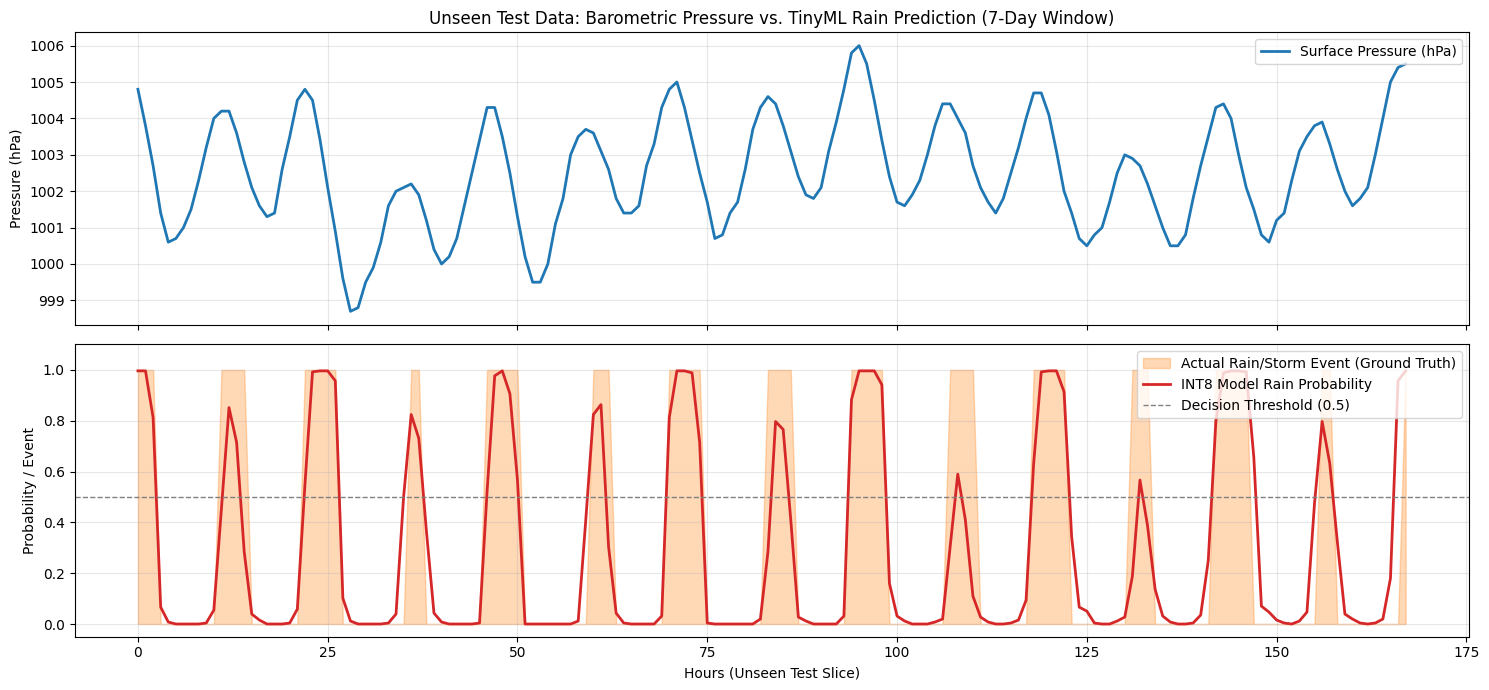

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ==========================================
# PLOT CONFUSION MATRIX & 7-DAY TIMELINE (NO RETRAINING NEEDED)
# ==========================================
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_int8)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("INT8 Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

# 7-Day (168-hour) unseen test timeline
slice_len = 168
start_idx = 200  # Adjust this offset to browse different weeks in the test set

hours = np.arange(slice_len)
test_pressure = X_test[start_idx : start_idx + slice_len, -1, 2]
actual_rain = (y_test[start_idx : start_idx + slice_len] == 1).astype(int)
pred_rain_prob = y_prob_rain[start_idx : start_idx + slice_len]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

ax1.plot(hours, test_pressure, color="#1f77b4", linewidth=2, label="Surface Pressure (hPa)")
ax1.set_ylabel("Pressure (hPa)")
ax1.set_title("Unseen Test Data: Barometric Pressure vs. TinyML Rain Prediction (7-Day Window)")
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)

ax2.fill_between(hours, 0, actual_rain, color="#ff7f0e", alpha=0.3, label="Actual Rain/Storm Event (Ground Truth)")
ax2.plot(hours, pred_rain_prob, color="#d62728", linewidth=2, label="INT8 Model Rain Probability")
ax2.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Decision Threshold (0.5)")
ax2.set_ylabel("Probability / Event")
ax2.set_xlabel("Hours (Unseen Test Slice)")
ax2.set_ylim(-0.05, 1.1)
ax2.legend(loc="upper right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()